# Workshop 2 — Results

This notebook does not train anything: it loads the saved checkpoint and the results of `src/train.py` and `src/evaluate.py`.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.model import count_parameters
from src.test_model import load_checkpoint, top5

## 1. Model

In [2]:
model, ckpt = load_checkpoint('../checkpoints/model_best.pt')
print(model)
print('Trainable parameters:', f'{count_parameters(model):,}')
print('Selected run:', ckpt['run_name'], '| best epoch:', ckpt['epoch'])
ckpt['train_hparams']

CharLSTM(
  (embedding): Embedding(76, 8)
  (lstm): ModuleList(
    (0): LSTM(8, 256, batch_first=True)
    (1): LSTM(256, 256, batch_first=True)
  )
  (dropout): Dropout(p=0.1, inplace=False)
  (fc): Linear(in_features=256, out_features=76, bias=True)
)
Trainable parameters: 818,860
Selected run: lstm_weighted | best epoch: 9


{'lr': 0.003,
 'weight_decay': 0.0001,
 'dropout': 0.1,
 'batch_size': 512,
 'epochs': 10,
 'class_weights': True,
 'max_train_samples': 1500000,
 'seed': 42,
 'optimizer': 'AdamW',
 'scheduler': 'CosineAnnealingLR',
 'clip_grad_norm': 5.0,
 'patience': 3}

A 2-layer LSTM with 256 units and about 819k parameters. It is small enough to train on our 4 GB GPU.

## 2. Hyperparameter search

In [3]:
pd.read_csv('../reports/hparam_search.csv').round(4)

,run_name,lr,dropout,weight_decay,best_epoch,val_f1_macro,val_accuracy,val_auc_ovr_subsample,minutes
0,search_lr0.003_do0.1_wd0.0001,0.0030,0.1,0.0001,4,0.1894,0.5200,0.9440,5.8257
1,search_lr0.003_do0.3_wd0.01,0.0030,0.3,0.0100,4,0.1780,0.5045,0.9399,6.0297
2,search_lr0.001_do0.3_wd0.01,0.0010,0.3,0.0100,4,0.1410,0.4588,0.9177,5.8556
3,search_lr0.001_do0.1_wd0.0001,0.0010,0.1,0.0001,4,0.1375,0.4503,0.9151,5.9265
4,search_lr0.0003_do0.1_wd0.0001,0.0003,0.1,0.0001,4,0.0827,0.3740,0.8760,5.9029
5,search_lr0.0003_do0.3_wd0.01,0.0003,0.3,0.0100,4,0.0795,0.3665,0.8750,5.8367


The learning rate matters most, and 3e-3 is clearly the best. With only 4 epochs the model is still underfitting, so the light regularisation (dropout 0.1, weight decay 1e-4) works better.

## 3. Learning curves of the two final variants

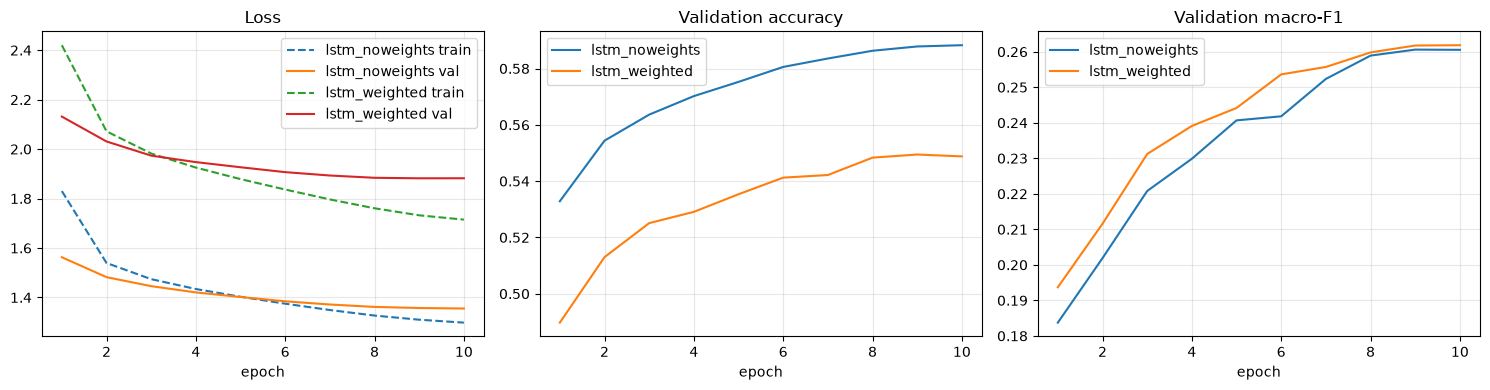

In [4]:
import torch
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ['lstm_noweights', 'lstm_weighted']:
    h = pd.DataFrame(torch.load(f'../checkpoints/{name}.pt', weights_only=False)['history'])
    axes[0].plot(h.epoch, h.train_loss, '--', label=f'{name} train')
    axes[0].plot(h.epoch, h.val_loss, label=f'{name} val')
    axes[1].plot(h.epoch, h.val_accuracy, label=name)
    axes[2].plot(h.epoch, h.val_f1_macro, label=name)
for ax, t in zip(axes, ['Loss', 'Validation accuracy', 'Validation macro-F1']):
    ax.set_title(t); ax.set_xlabel('epoch'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Train and validation losses go down together and stay close, so there is no overfitting. At the end the curves are almost flat (cosine schedule), so 10 epochs were enough. The weighted model has a higher loss (the weights change the scale of the loss) and a lower accuracy, but a slightly better macro-F1, so it was selected.

## 4. Final metrics and comparison with Workshop 1

In [5]:
pd.DataFrame({'train (200k subsample)': ckpt['final_metrics']['train_subsample'],
              'validation': ckpt['final_metrics']['val']}).loc[
    ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'auc_roc_ovr_macro']].round(4)

,train (200k subsample),validation
accuracy,0.5728,0.5495
precision_macro,0.3705,0.2734
recall_macro,0.4243,0.2949
f1_macro,0.3572,0.2617
f1_weighted,0.5869,0.5635
auc_roc_ovr_macro,0.9743,0.9566


In [6]:
pd.read_csv('../reports/results_comparison.csv').round(4)

,model,accuracy,precision_macro,precision_weighted,recall_macro,recall_weighted,f1_macro,f1_weighted,auc_roc_ovr_macro
0,Majority class (space),0.1832,0.0029,0.0336,0.0159,0.1832,0.0049,0.0567,0.5000
1,Logistic regression (W1),0.3689,0.1575,0.3180,0.1031,0.3689,0.1082,0.3236,0.8710
2,Naive Bayes (W1),0.3339,0.1175,0.2986,0.1167,0.3339,0.1074,0.3040,0.8487
3,Random forest (W1),0.3075,0.1587,0.4735,0.1761,0.3075,0.1402,0.3497,0.8196
4,LSTM without class weights,0.5896,0.4276,0.5921,0.2748,0.5896,0.3051,0.5745,0.9650
5,LSTM with class weights (selected),0.5571,0.3258,0.5972,0.3300,0.5571,0.3007,0.5707,0.9619


Test metrics are on the same 10k test rows used for the Workshop 1 baselines. The LSTM is much better than every baseline (accuracy ~0.56-0.59 vs 0.37, macro-F1 ~0.30 vs 0.14) because it uses the 80 previous characters, while the baselines only used the last 5. Train, validation and test results are similar, so the model works on speakers it never saw.

## 5. Error analysis

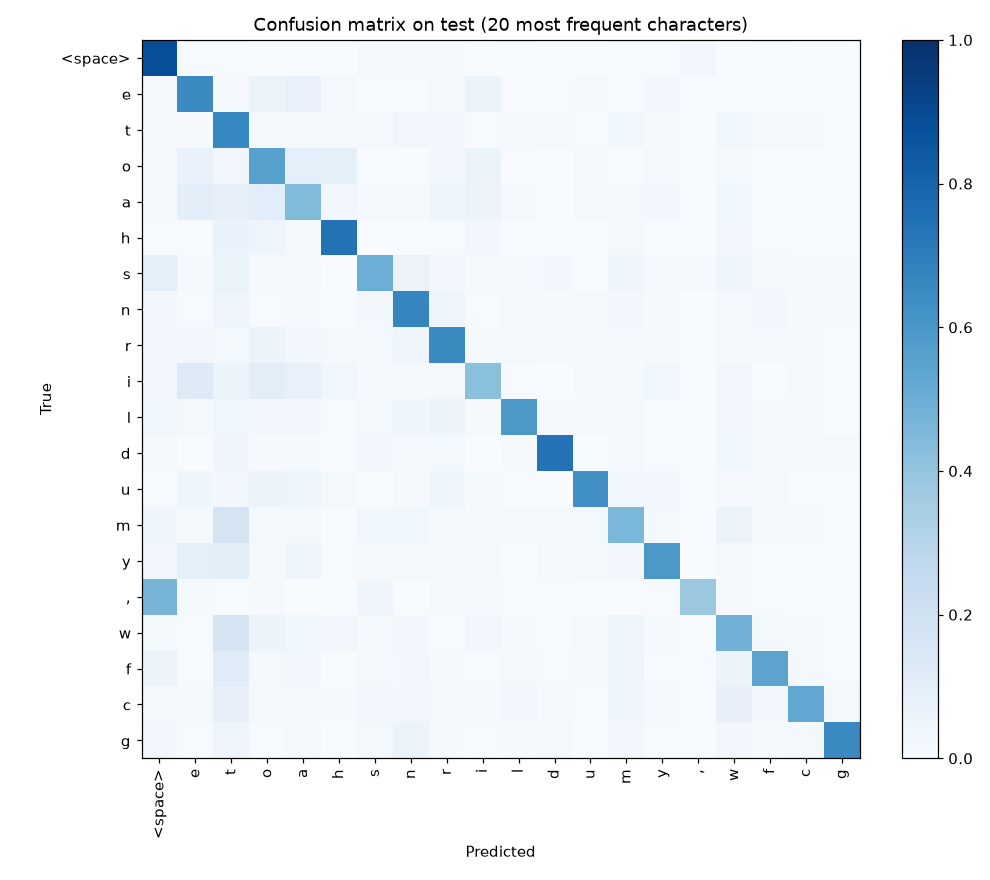

In [7]:
display(Image('../reports/figures/confusion_matrix_top20.png'))

The model predicts the space and common lowercase letters well (space ~80% correct). It fails with uppercase letters and punctuation like `;` or `:` (below 10%), because the start of a new word or sentence is hard to guess. Most errors are between similar characters, for example vowels with each other.

## 6. Predictions on new text

In [8]:
vocab = ckpt['vocab']
for text in ['To be, or not to be, that is the questio', 'My lord, I come to tell you that the kin']:
    print(repr(text), '->', [(c, round(p, 3)) for c, p in top5(model, text, vocab)])

'To be, or not to be, that is the questio' -> [('n', 0.997), ('u', 0.001), ('t', 0.001), ('l', 0.0), ('r', 0.0)]
'My lord, I come to tell you that the kin' -> [('g', 0.702), ('d', 0.242), ('s', 0.026), ('.', 0.005), (',', 0.005)]


The model completes common words with high probability, so it learned spelling and typical words of Shakespeare.